# Student Lifestyle and Academic Performance

This notebook looks at daily routines, stress levels, and GPA in the student lifestyle dataset. The charts and summaries describe patterns in the data; they do not explain what causes them.

## Loading the data



In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [17]:
df = pd.read_csv("student_lifestyle_dataset.csv")

print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")
print(f"Missing values: {df.isna().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")
display(df.head())

Rows: 2,000
Columns: 8
Missing values: 0
Duplicate rows: 0


,Student_ID,Study_Hours_Per_Day,Extracurricular_Hours_Per_Day,Sleep_Hours_Per_Day,Social_Hours_Per_Day,Physical_Activity_Hours_Per_Day,GPA,Stress_Level
0,1,6.9,3.8,8.7,2.8,1.8,2.99,Moderate
1,2,5.3,3.5,8.0,4.2,3.0,2.75,Low
2,3,5.1,3.9,9.2,1.2,4.6,2.67,Low
3,4,6.5,2.1,7.2,1.7,6.5,2.88,Moderate
4,5,8.1,0.6,6.5,2.2,6.6,3.51,High


In [18]:
display(df.drop(columns="Student_ID").describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Study_Hours_Per_Day,2000.0,7.48,1.42,5.00,6.3,7.40,8.70,10.0
Extracurricular_Hours_Per_Day,2000.0,1.99,1.16,0.00,1.0,2.00,3.00,4.0
Sleep_Hours_Per_Day,2000.0,7.50,1.46,5.00,6.2,7.50,8.80,10.0
Social_Hours_Per_Day,2000.0,2.70,1.69,0.00,1.2,2.60,4.10,6.0
Physical_Activity_Hours_Per_Day,2000.0,4.33,2.51,0.00,2.4,4.10,6.10,13.0
GPA,2000.0,3.12,0.30,2.24,2.9,3.11,3.33,4.0


## Stress levels

Comparing the number of students in each stress group.

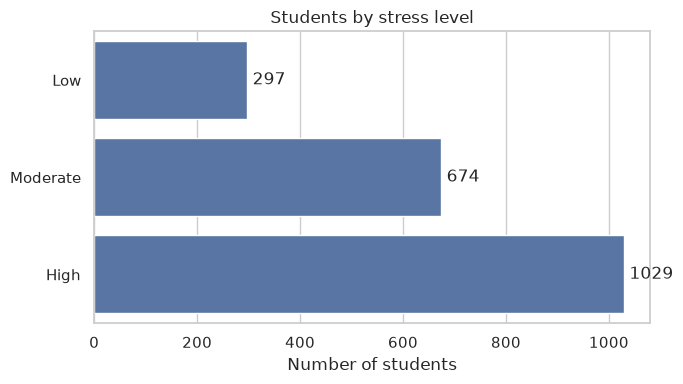

In [19]:
stress_order = ["Low", "Moderate", "High"]

fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, y="Stress_Level", order=stress_order, color="#4c72b0", ax=ax)
ax.set(title="Students by stress level", xlabel="Number of students", ylabel="")
ax.bar_label(ax.containers[0], padding=4)
plt.tight_layout()
plt.show()

## Daily routines

These charts show how the reported hours and GPA are spread across the students in the dataset.

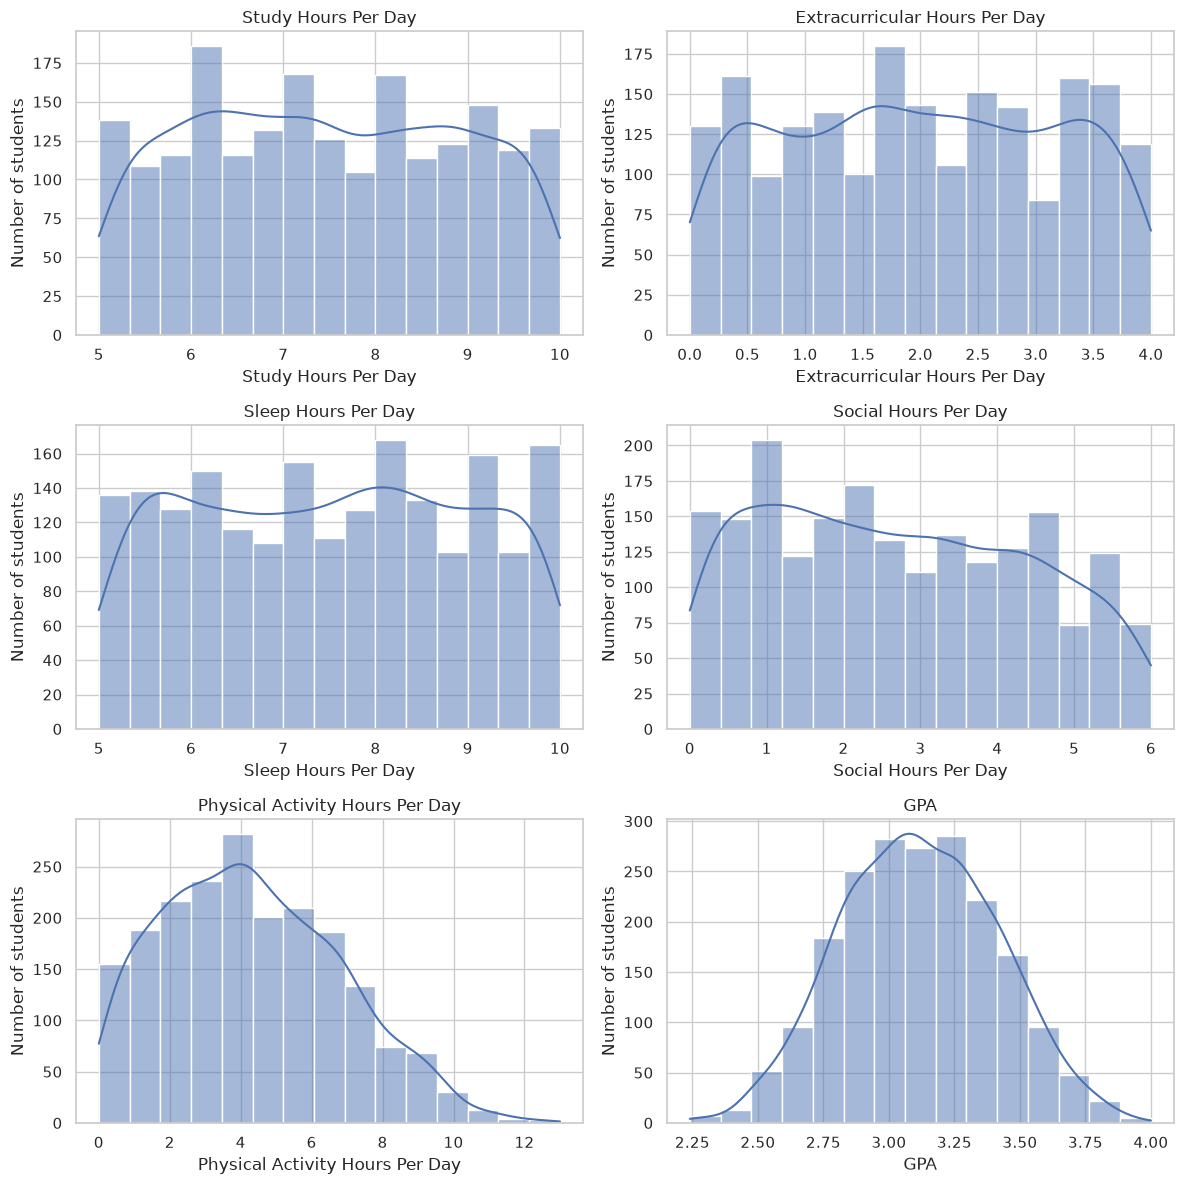

In [20]:
columns_to_plot = [
    "Study_Hours_Per_Day",
    "Extracurricular_Hours_Per_Day",
    "Sleep_Hours_Per_Day",
    "Social_Hours_Per_Day",
    "Physical_Activity_Hours_Per_Day",
    "GPA",
]

fig, axes = plt.subplots(3, 2, figsize=(12, 12))
for ax, column in zip(axes.flat, columns_to_plot):
    label = column.replace("_", " ")
    sns.histplot(data=df, x=column, bins=15, kde=True, color="#4c72b0", ax=ax)
    ax.set(title=label, xlabel=label, ylabel="Number of students")

plt.tight_layout()
plt.show()

## GPA and stress

Compare GPA across the three stress groups. The box plots show the spread of scores, not just the average.

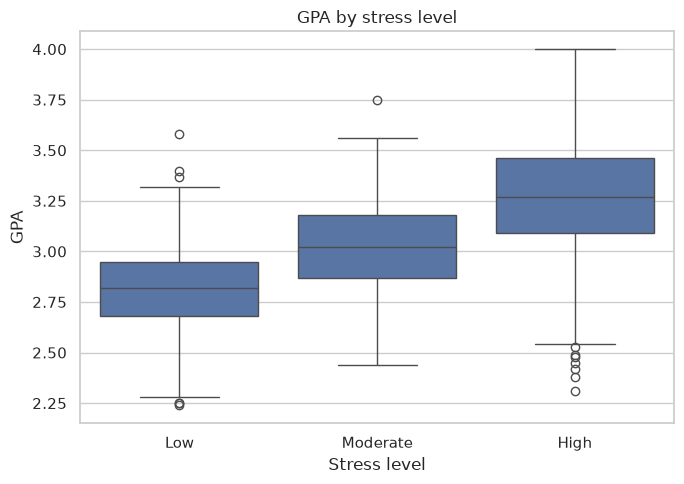

In [21]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(
    data=df,
    x="Stress_Level",
    y="GPA",
    order=stress_order,
    color="#4c72b0",
    ax=ax,
)
ax.set(title="GPA by stress level", xlabel="Stress level", ylabel="GPA")
plt.tight_layout()
plt.show()

## Daily routines by stress level

Compare study, sleep, activity, social, and extracurricular hours across stress groups.

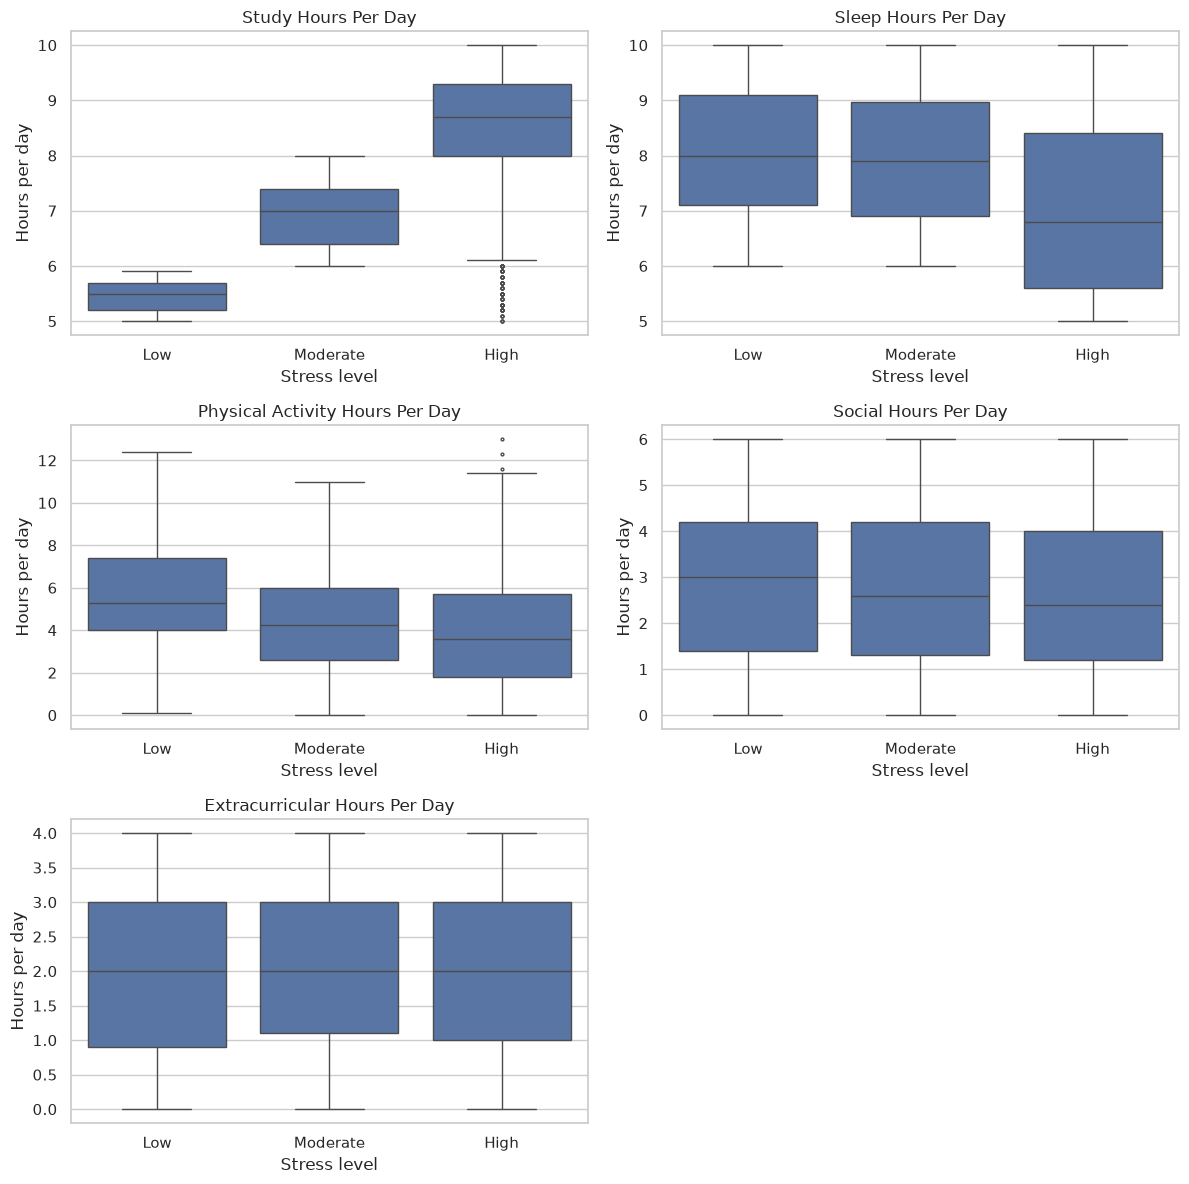

In [22]:
routine_columns = [
    "Study_Hours_Per_Day",
    "Sleep_Hours_Per_Day",
    "Physical_Activity_Hours_Per_Day",
    "Social_Hours_Per_Day",
    "Extracurricular_Hours_Per_Day",
]

fig, axes = plt.subplots(3, 2, figsize=(12, 12))
for ax, column in zip(axes.flat, routine_columns):
    label = column.replace("_", " ")
    sns.boxplot(
        data=df,
        x="Stress_Level",
        y=column,
        order=stress_order,
        color="#4c72b0",
        fliersize=2,
        ax=ax,
    )
    ax.set(title=label, xlabel="Stress level", ylabel="Hours per day")

axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

## Group averages and GPA relationships

The averages make it easier to compare the stress groups. The correlations describe how two numeric columns vary together in this dataset.

In [23]:
group_averages = (
    df.groupby("Stress_Level")[["GPA", "Study_Hours_Per_Day", "Sleep_Hours_Per_Day", "Physical_Activity_Hours_Per_Day"]]
    .mean()
    .reindex(stress_order)
    .round(2)
)
display(group_averages)

gpa_correlations = (
    df[["Study_Hours_Per_Day", "Sleep_Hours_Per_Day", "Physical_Activity_Hours_Per_Day", "Social_Hours_Per_Day", "Extracurricular_Hours_Per_Day", "GPA"]]
    .corr()["GPA"]
    .drop("GPA")
    .sort_values(ascending=False)
    .round(3)
    .to_frame("Correlation with GPA")
)
display(gpa_correlations)

,GPA,Study_Hours_Per_Day,Sleep_Hours_Per_Day,Physical_Activity_Hours_Per_Day
Stress_Level,,,,
Low,2.82,5.47,8.06,5.58
Moderate,3.02,6.97,7.95,4.34
High,3.26,8.39,7.05,3.96


,Correlation with GPA
Study_Hours_Per_Day,0.734
Sleep_Hours_Per_Day,-0.004
Extracurricular_Hours_Per_Day,-0.032
Social_Hours_Per_Day,-0.086
Physical_Activity_Hours_Per_Day,-0.341


## Conclusions drawn so far

The dataset contains 2,000 student records. High stress is the largest group, with 1,029 students (51.4%).

Students in the high-stress group report an average of 8.39 study hours per day and an average GPA of 3.26. In the low-stress group, the averages are 5.47 study hours and a GPA of 2.82. In this dataset, study hours and GPA tend to rise together (correlation: 0.734). Physical activity and GPA have a smaller negative relationship (correlation: -0.341).

These results describe this dataset only. They do not show that stress, study time, or physical activity causes a change in GPA.